Performing AI/ML Assignment 2,
Student Name : Mary Shirly S
ID: 2026AK05393
Subject : Machine Learning

In [4]:
from google.colab import files
uploaded = files.upload() # pick Telco-Customer-Churn.csv

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn (1).csv


Data loaded,
Inspect data now

In [5]:
import pandas as pd
import numpy as np

df =pd.read_csv("Telco-Customer-Churn.csv")
print ("Shape:",df.shape)
print()
df.info()
print()
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))
df.head()

Shape: (7043, 21)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Shape: (7043, 21) , dftype for totalCharges is Object and not number. Churn is 73.5% No and Yes is 26.5%, the classes are imbalanced. that is why we look at AUC, Recall, F1, and MCC and not only Accuracy.

Lets clean the Data

In [6]:
# customerID is just an Identifier, not a feature
df =df.drop(columns=["customerID"])

In [7]:
# TotalCharges is text because some rows contain a blank space
df["TotalCharges"] =pd.to_numeric(df["TotalCharges"], errors="coerce")

In [8]:
print("Missing values per column (only those above 0)")
missing =df.isna().sum()
print(missing[missing >0])
print()
print("Tenure of the rows with missing TotalCharges:")
print(df.loc[df["TotalCharges"].isna(), "tenure"].unique())

#Only 11 rows, so drop them
df=df.dropna().reset_index(drop=True)
print()
print("Shape after clarning:", df.shape)


Missing values per column (only those above 0)
TotalCharges    11
dtype: int64

Tenure of the rows with missing TotalCharges:
[0]

Shape after clarning: (7032, 20)


In [9]:
from sklearn.model_selection import train_test_split

Seed = 42
TARGET = "Churn"

X = df.drop(columns=[TARGET])
y = (df[TARGET] == "Yes").astype(int)  # Yes ->1, No ->0

X_train, X_test, y_train, y_test = train_test_split (X,y, test_size=0.2, stratify=y, random_state=Seed)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 3), "test:", round(y_test.mean(), 3))


Train: (5625, 19) Test: (1407, 19)
Churn rate train: 0.266 test: 0.266


Preprocessing

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

print("Numeric:", num_cols)
print("Categorical:", cat_cols)

def make_preprocessor():
  return ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
  ])

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Training all 5 Models

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=Seed),
    "decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=Seed),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, probability=True, random_state=Seed),
}

print(list(models))

['Logistic Regression', 'decision Tree', 'KNN', 'Naive Bayes', 'Support Vector Machine']


In [12]:
from sklearn.pipeline import Pipeline

fitted = {}
for name, clf in models.items():
  pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
  pipe.fit(X_train, y_train)
  fitted[name] = pipe
  print("trained:", name)

trained: Logistic Regression
trained: decision Tree
trained: KNN
trained: Naive Bayes
trained: Support Vector Machine


We now evaluate 6 metrics for each model

In [13]:
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef)

rows = []
preds = {}

for name, pipe in fitted.items():
  pred = pipe.predict(X_test)
  proba = pipe.predict_proba(X_test)[:, 1]
  preds[name] = pred

  rows.append({
      "ML Model Name": name,
      "Accuracy": accuracy_score(y_test, pred),
      "AUC": roc_auc_score(y_test, proba),
      "Precision": precision_score(y_test, pred),
      "Recall": recall_score(y_test, pred),
      "F1": f1_score(y_test, pred),
      "MCC": matthews_corrcoef(y_test, pred),
  })

  metrics =pd.DataFrame(rows).round(4)
  print(metrics.to_string(index=False)) # plain-text table, always visible
  display(metrics)  # nicer table view in Colab

      ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
Logistic Regression    0.8045 0.8359     0.6495  0.5749 0.6099 0.4818


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8045,0.8359,0.6495,0.5749,0.6099,0.4818


      ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
Logistic Regression    0.8045 0.8359     0.6495  0.5749 0.6099 0.4818
      decision Tree    0.7903 0.8264     0.6037  0.6150 0.6093 0.4661


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8045,0.8359,0.6495,0.5749,0.6099,0.4818
1,decision Tree,0.7903,0.8264,0.6037,0.6150,0.6093,0.4661


      ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
Logistic Regression    0.8045 0.8359     0.6495  0.5749 0.6099 0.4818
      decision Tree    0.7903 0.8264     0.6037  0.6150 0.6093 0.4661
                KNN    0.7605 0.7818     0.5457  0.5909 0.5674 0.4028


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8045,0.8359,0.6495,0.5749,0.6099,0.4818
1,decision Tree,0.7903,0.8264,0.6037,0.6150,0.6093,0.4661
2,KNN,0.7605,0.7818,0.5457,0.5909,0.5674,0.4028


      ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
Logistic Regression    0.8045 0.8359     0.6495  0.5749 0.6099 0.4818
      decision Tree    0.7903 0.8264     0.6037  0.6150 0.6093 0.4661
                KNN    0.7605 0.7818     0.5457  0.5909 0.5674 0.4028
        Naive Bayes    0.6844 0.8040     0.4493  0.8289 0.5827 0.4074


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8045,0.8359,0.6495,0.5749,0.6099,0.4818
1,decision Tree,0.7903,0.8264,0.6037,0.6150,0.6093,0.4661
2,KNN,0.7605,0.7818,0.5457,0.5909,0.5674,0.4028
3,Naive Bayes,0.6844,0.8040,0.4493,0.8289,0.5827,0.4074


         ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.8045 0.8359     0.6495  0.5749 0.6099 0.4818
         decision Tree    0.7903 0.8264     0.6037  0.6150 0.6093 0.4661
                   KNN    0.7605 0.7818     0.5457  0.5909 0.5674 0.4028
           Naive Bayes    0.6844 0.8040     0.4493  0.8289 0.5827 0.4074
Support Vector Machine    0.7939 0.7842     0.6458  0.4973 0.5619 0.4364


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8045,0.8359,0.6495,0.5749,0.6099,0.4818
1,decision Tree,0.7903,0.8264,0.6037,0.6150,0.6093,0.4661
2,KNN,0.7605,0.7818,0.5457,0.5909,0.5674,0.4028
3,Naive Bayes,0.6844,0.8040,0.4493,0.8289,0.5827,0.4074
4,Support Vector Machine,0.7939,0.7842,0.6458,0.4973,0.5619,0.4364


In [14]:
for col in ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]:
  top = metrics.loc[metrics[col].idxmax()]
  low = metrics.loc[metrics[col].idxmin()]
  print(f"{col:10s} best: {top['ML Model Name']} ({top[col]}) worst: {low['ML Model Name']} ({low[col]})")

Accuracy   best: Logistic Regression (0.8045) worst: Naive Bayes (0.6844)
AUC        best: Logistic Regression (0.8359) worst: KNN (0.7818)
Precision  best: Logistic Regression (0.6495) worst: Naive Bayes (0.4493)
Recall     best: Naive Bayes (0.8289) worst: Support Vector Machine (0.4973)
F1         best: Logistic Regression (0.6099) worst: Support Vector Machine (0.5619)
MCC        best: Logistic Regression (0.4818) worst: KNN (0.4028)


Summary :


1. Logistic Regression is the best overall model. Accuracy (0.8045), AUC (0.8359), Precision (0.6495), F1 (0.6099) and MCC (0.4818).
2. Naive Bayes has the highest recall (Recall 0.8289) but the lowest precision and accuracy.
3. SVM is the most conservative model, lowest Recall (0.4973)
4. KNN ranks the weakest overall.
5. Decision Tree is consistently in the middle.





Conclusion

Logistic Regression is the recommended model. It has the best balance between catching churners and avoiding false alarms (highest F1 and MCC), the best ranking ability (AUC 0.8359), and it is easy to interpret. The Decision Tree is a strong alternative when more recall or explainable rules are needed.

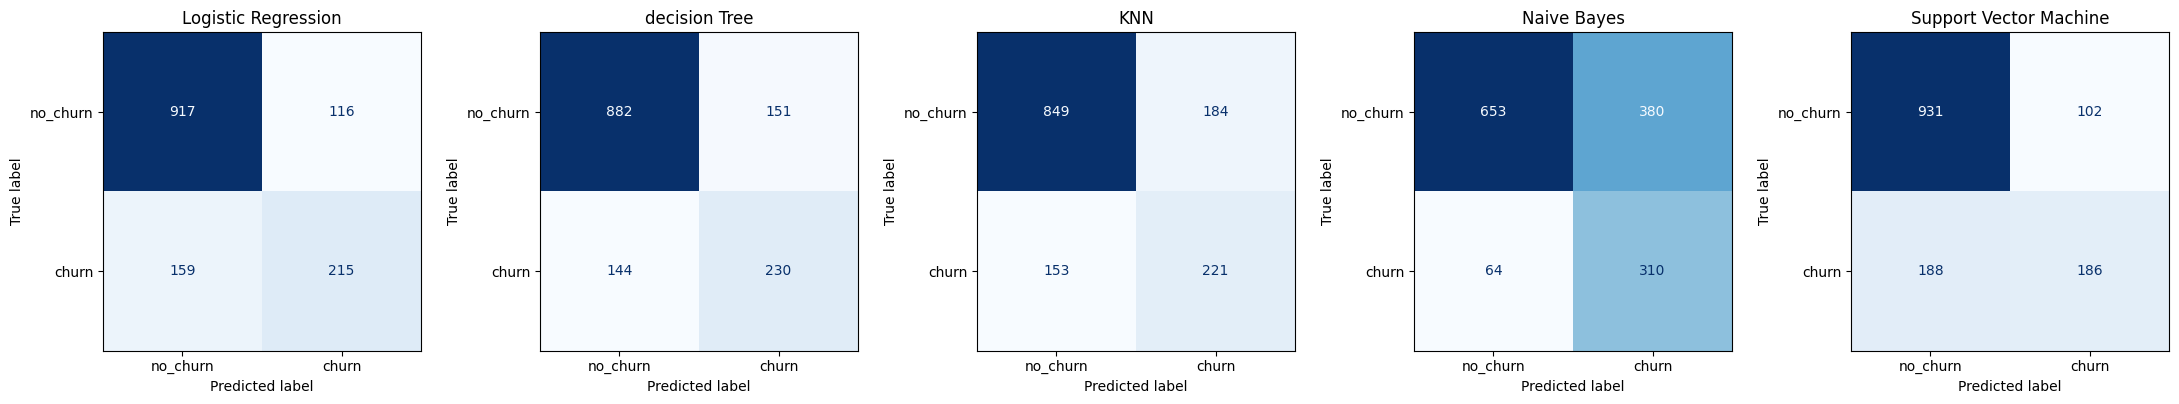

classification report for best model by MCC: Logistic Regression
              precision    recall  f1-score   support

    No_churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, pred) in zip(axes, preds.items()):
  ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["no_churn", "churn"], ax=ax, cmap="Blues", colorbar=False)
  ax.set_title(name)
plt.tight_layout()
plt.show()

best = metrics.sort_values("MCC", ascending=False).iloc[0]["ML Model Name"]
print("classification report for best model by MCC:", best)
print(classification_report(y_test, preds[best], target_names=["No_churn", "Churn"]))


In [16]:
import os, joblib, sklearn
os.makedirs("model", exist_ok=True)

for name, pipe in fitted.items():
  fname = name.lower().replace(" ", "_") + ".joblib"
  joblib.dump(pipe, "model/" + fname)

metrics.to_csv("model/metric.csv", index=False)


# held-out test data (with the Churn column as Yes/No) for the Streamlit upload

In [17]:
# Reconstruct the original test dataframe with the categorical 'Yes'/'No' Churn target
test_out = X_test.copy()
test_out[TARGET] = y_test.map({1: 'Yes', 0: 'No'})

# Save to csv for Streamlit upload
test_out.to_csv("model/held_out_test_data.csv", index=False)
print("Saved held-out test data with shape:", test_out.shape)
test_out.head()

Saved held-out test data with shape: (1407, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
971,Female,0,Yes,Yes,59,Yes,No,DSL,No,Yes,No,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),75.95,4542.35,No
618,Female,0,No,No,7,Yes,Yes,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),78.55,522.95,No
4282,Female,0,No,No,54,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.10,1079.45,No
3715,Female,0,No,No,2,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.65,38.70,Yes
4525,Female,0,Yes,No,71,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.15,7555.00,No


In [18]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from google.colab import files

# Ensure variables are defined by loading and splitting data if they are missing from memory
if 'X_test' not in globals() or 'y_test' not in globals():
    filename = "Telco-Customer-Churn.csv"
    if not os.path.exists(filename):
        print(f"'{filename}' not found in the current directory. Please upload it below:")
        uploaded = files.upload()

    df_temp = pd.read_csv(filename)
    df_temp = df_temp.drop(columns=["customerID"])
    df_temp["TotalCharges"] = pd.to_numeric(df_temp["TotalCharges"], errors="coerce")
    df_temp = df_temp.dropna().reset_index(drop=True)

    TARGET = "Churn"
    X_temp = df_temp.drop(columns=[TARGET])
    y_temp = (df_temp[TARGET] == "Yes").astype(int)

    _, X_test, _, y_test = train_test_split(X_temp, y_temp, test_size=0.2, stratify=y_temp, random_state=42)
    TARGET_VAR = TARGET
else:
    TARGET_VAR = TARGET if 'TARGET' in globals() else 'Churn'

# Create and save the held-out test data
test_out = X_test.copy()
test_out[TARGET_VAR] = y_test.map({1: 'Yes', 0: 'No'})
test_out.to_csv("test_data.csv", index=False)
print("Saved held-out test data with shape:", test_out.shape)

Saved held-out test data with shape: (1407, 20)


In [19]:
import sklearn
import os

# requirements.txt pinned to the sklearn version used here
with open("requirements.txt", "w") as f:
    f.write("streamlit\n")
    f.write("scikit-learn==" + sklearn.__version__ + "\n")
    f.write("numpy\npandas\nmatplotlib\njoblib\n")

print("scikit-learn version used for training:", sklearn.__version__)
print(open("requirements.txt").read())
print(sorted(os.listdir("model")))
print(open("model/metric.csv").read())
print(open("test_data.csv").read())

scikit-learn version used for training: 1.6.1
streamlit
scikit-learn==1.6.1
numpy
pandas
matplotlib
joblib

['decision_tree.joblib', 'held_out_test_data.csv', 'knn.joblib', 'logistic_regression.joblib', 'metric.csv', 'naive_bayes.joblib', 'support_vector_machine.joblib']
ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8045,0.8359,0.6495,0.5749,0.6099,0.4818
decision Tree,0.7903,0.8264,0.6037,0.615,0.6093,0.4661
KNN,0.7605,0.7818,0.5457,0.5909,0.5674,0.4028
Naive Bayes,0.6844,0.804,0.4493,0.8289,0.5827,0.4074
Support Vector Machine,0.7939,0.7842,0.6458,0.4973,0.5619,0.4364

gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
Female,0,Yes,Yes,59,Yes,No,DSL,No,Yes,No,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),75.95,4542.35,No
Female,0,No,No,7,Yes,Yes,Fiber optic,No

In [24]:
import shutil
shutil.make_archive("telco_project_files", "zip", "model")
files.download("telco_project_files.zip")  #models + metrics.csv
files.download("test_data.csv")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>